
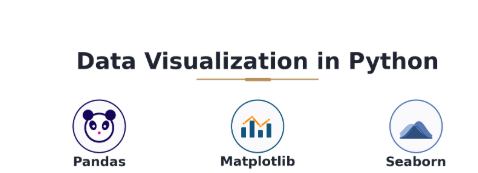

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# read the file
df = pd.read_excel('/Users/riteshpardeshi/Downloads/BI.xlsx')

In [5]:
df.head()

,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost
0,Central,Antigua,Baby Food,Online,Medium,2019-12-20,957081544.0,2019-01-11,552,255.28,159.42
1,Central,Panama,Snacks,Offline,Cancelled,2022-07-05,301644504.0,2022-07-26,2167,152.58,97.44
2,Europe,Czech Rep.,Beverages,Offline,Cancelled,2021-09-12,478051030.0,2021-09-29,4778,47.45,31.79
3,Asia,North Korea,Cereal,Offline,Low,2022-05-13,892599952.0,2022-06-15,9016,205.70,117.11
4,Asia,Sri Lanka,Snacks,Offline,Cancelled,2015-07-20,571902596.0,2015-07-27,7542,152.58,97.44


In [6]:
df.columns = [c.strip().replace(' ','_') for c in df.columns]

In [7]:
# Derive the business metrics every chart below will use ---

df['Revenue']  = df['Units_Sold'] * df['Unit_Price']
df['Cost']     = df['Units_Sold'] * df['Unit_Cost']
df['Profit']   = df['Revenue'] - df['Cost']
df['Margin %'] = (df['Profit'] / df['Revenue']) * 100
df['Order_Month'] = df['Order_Date'].dt.to_period('M').dt.to_timestamp()


df.head()

,Region,Country,Item_Type,Sales_Channel,Order_Priority,Order_Date,Order_ID,Ship_Date,Units_Sold,Unit_Price,Unit_Cost,Revenue,Cost,Profit,Margin %,Order_Month
0,Central,Antigua,Baby Food,Online,Medium,2019-12-20,957081544.0,2019-01-11,552,255.28,159.42,140914.56,87999.84,52914.72,37.550924,2019-12-01
1,Central,Panama,Snacks,Offline,Cancelled,2022-07-05,301644504.0,2022-07-26,2167,152.58,97.44,330640.86,211152.48,119488.38,36.138419,2022-07-01
2,Europe,Czech Rep.,Beverages,Offline,Cancelled,2021-09-12,478051030.0,2021-09-29,4778,47.45,31.79,226716.10,151892.62,74823.48,33.003161,2021-09-01
3,Asia,North Korea,Cereal,Offline,Low,2022-05-13,892599952.0,2022-06-15,9016,205.70,117.11,1854591.20,1055863.76,798727.44,43.067574,2022-05-01
4,Asia,Sri Lanka,Snacks,Offline,Cancelled,2015-07-20,571902596.0,2015-07-27,7542,152.58,97.44,1150758.36,734892.48,415865.88,36.138419,2015-07-01


<div class="alert" style="background-color:maroon; color:#800000; padding:0px 5px; border-radius:5px;"><h3 style='margin:15px 15px; color:#ffffff; font-size:30px'> Plotting in Pandas </h3>
</div>


Pandas does not have its own drawing engine. 

Every `Series` and `DataFrame` carries a `.plot()` **accessor** which is a thin wrapper: internally it calls **Matplotlib** to do the actual drawing, then hands back the Matplotlib `Axes` object it drew on.



- 1.     `.plot()` accepts a `kind=` argument (`'bar'`, `'pie'`, `'scatter'` etc. ...) that just routes to the matching Matplotlib call.
  
- 2.       Because it returns a real Matplotlib `Axes`, you can customize with ordinary Matplotlib methods right after calling `.plot()`
  
- 3.       If Matplotlib is not installed, `.plot()` fails outright - it is not an independent engine, it is a convenience layer on top of one.


<Axes: ylabel='Revenue'>

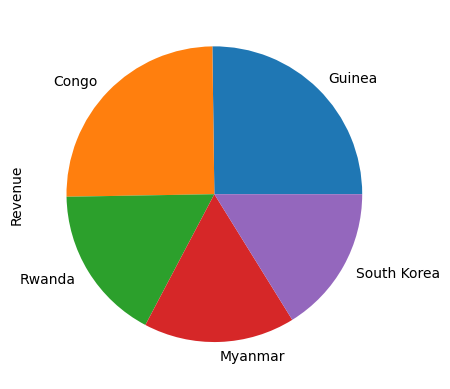

In [8]:
#1.1 Top 5 countries by revenue
df.head()
df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(5).plot(kind ='pie')

<Axes: xlabel='Country'>

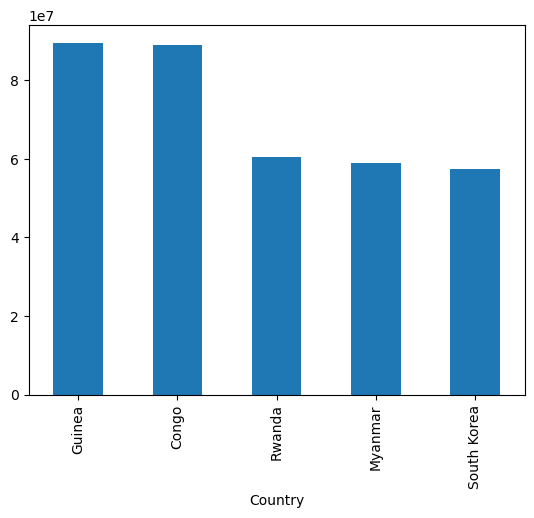

In [9]:
#1.2  Top 5 countries by revenue
df.head()
df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(5).plot(kind ='bar')

<Axes: ylabel='Country'>

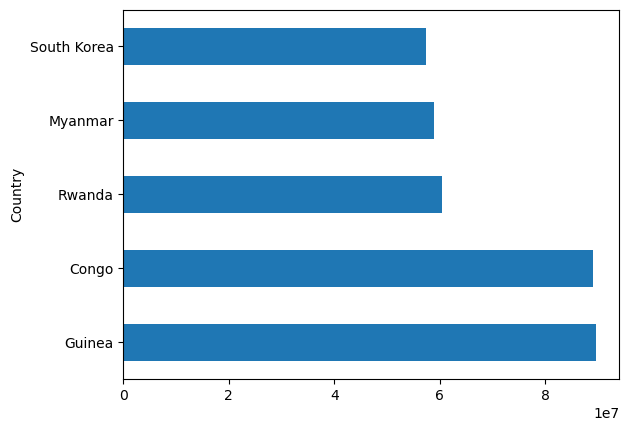

In [10]:
#1.3 Top 5 countries by revenue (horizontal bar chart)
df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(5).plot(kind ='barh')

<Axes: xlabel='Order_Month'>

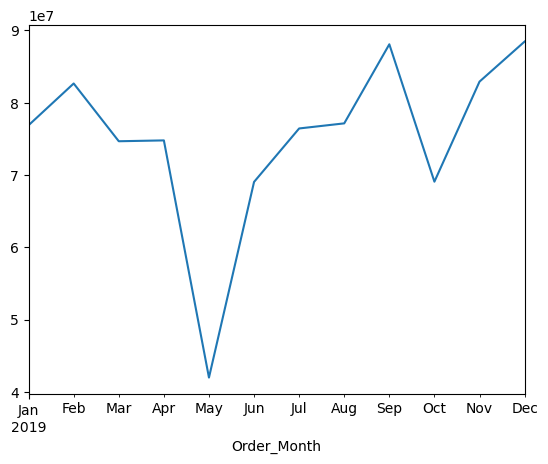

In [11]:
# 1.4 How has total monthly revenue trended over time in the year 2019
df[df['Order_Date'].dt.year == 2019].groupby('Order_Month')['Revenue'].sum().plot(kind='line')



<div class="alert" style="background-color:maroon; color:#800000; padding:0px 5px; border-radius:5px;"><h3 style='margin:15px 15px; color:#ffffff; font-size:30px'> Matplotlib </h3>
</div>


1. Matplotlib is the foundational plotting library in the Python data stack.
2. It is the engine that Pandas' `.plot()` (and Seaborn) both sit on top of. 
3. Working with it directly trades a little convenience for full control.

Every Matplotlib chart is built from two objects:

1. A **Figure** - the overall canvas / window that everything is drawn on.
2. One or more **Axes** - the actual plotting area inside the figure
  
  
A figure can hold many axes side by side - this is what "subplots" means (covered in 2d).

<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.1 Bar Chart </h5>
</div>




### As a Data Scientist, build a standalone chart for a slide deck that represents the sum of units sold by Item Type


In [19]:
# Step 1 - Get the data into a variable
sumofunits = df.groupby('Item_Type')['Units_Sold'].sum().sort_values(ascending=False)

In [20]:
#Step 2 - Cross check the data
sumofunits


Item_Type
Fruits             2341083
Baby Food          2277487
Beverages          2208169
Cosmetics          2150104
Personal Care      2134895
Office Supplies    2101964
Household          2099238
Vegetables         2075835
Clothes            1983445
Cereal             1943320
Snacks             1913975
Meat               1899406
Name: Units_Sold, dtype: int64

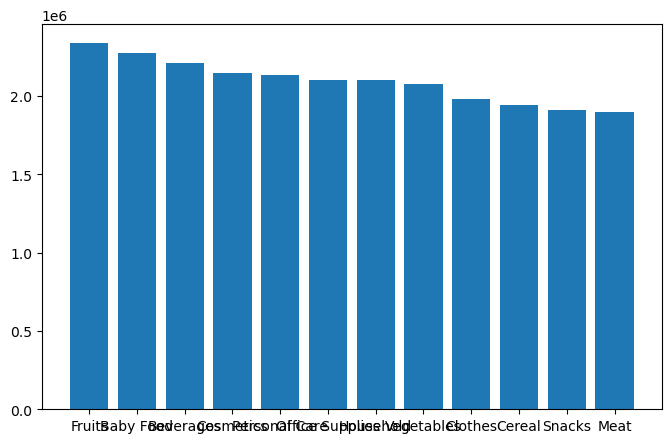

In [21]:
#Step 3 - Create the maptplotlib Canvas (fig) and plotting area (ax) and draw the chart into in it
fig, ax = plt.subplots(figsize=(8, 5))

 

ax.bar(x = sumofunits.index, height =sumofunits.values);







C:\Users\rohit\AppData\Local\Temp\ipykernel_11740\3341011425.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sumofunits.index, rotation=45, fontsize=12, color='black')


[Text(0, 1900000, '1.9Mil'),
 Text(0, 2100000, '2.1Mil'),
 Text(0, 2300000, '2.3Mil')]

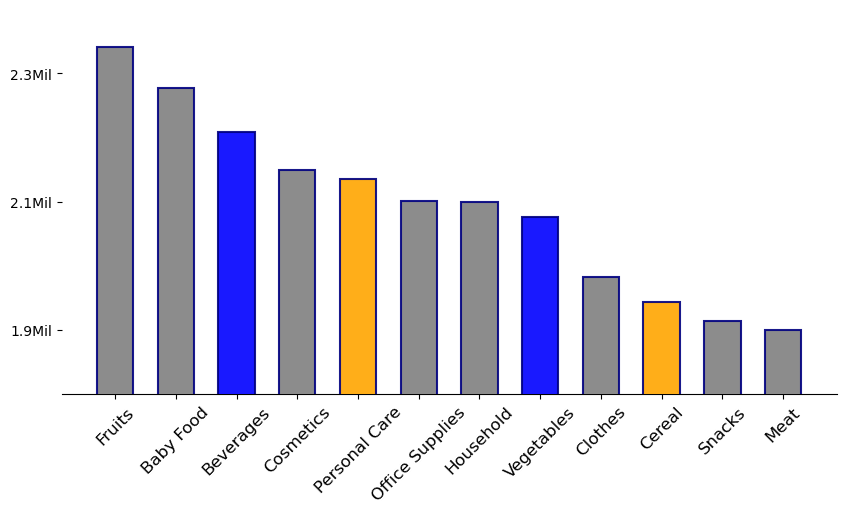

In [22]:
# Step 4 - Verify that you get the desired chart

 

# 1. Create the figure and axes objects

fig, ax = plt.subplots(figsize=(10, 5))

 

my_colors = ['grey', 'grey', 'blue', 'grey', 'orange']

 

# 2. Plot the bar chart using ax.bar

ax.bar(

    sumofunits.index,  # X-axis: Categories

    sumofunits.values,  # Y-axis: Numeric values

    width=0.6,  # Thickness of the bars

    color=my_colors,  # List of colors

    edgecolor='navy',  # Color of the bar border

    linewidth=1.5,  # Thickness of the border

    alpha=0.9,  # Transparency

    label='Q3 Revenue',  # Label for legend

    capsize=4,  # Width of the horizontal caps on error bars

    align='center',  # Alignment of the bar on the x-tick

    bottom=0,  # The base y-coordinate

    zorder=3,  # Drawing order

)

 

ax.set_xticklabels(sumofunits.index, rotation=45, fontsize=12, color='black')

 

 

ax.spines['top'].set_visible(False)

ax.spines['right'].set_visible(False)

ax.spines['left'].set_visible(False)

 

ax.set_ylim(1800000, 2400000)

ax.set_yticks([1900000, 2100000, 2300000])

ax.set_yticklabels(['1.9Mil', '2.1Mil', '2.3Mil'])






<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.2 Horizontal Bar Chart </h5>
</div>


<BarContainer object of 7 artists>

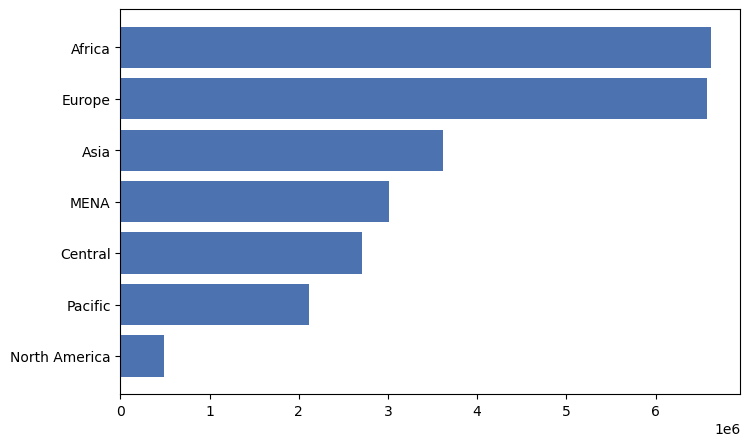

In [26]:
# Group Units Sold by Region, sum each group, then sort ascending

df.columns
df.groupby('Region')['Units_Sold'].sum().sort_values(ascending=True)

# Create a figure and a single axes to draw on, sized 8x5 inches

region_units = df.groupby('Region')['Units_Sold'].sum().sort_values(ascending=True)

 

 

# Create a figure and a single axes to draw on, sized 8x5 inches

 

fig, ax = plt.subplots(figsize=(8, 5))

 

# Draw horizontal bars: one per region, length = total units sold

ax.barh(region_units.index, region_units.values, color='#4C72B0')





# Draw horizontal bars: one per region, length = total units sold




# Set the chart title, bold and slightly larger than default

# Label the x-axis, since values now run horizontally (not the y-axis)

# Hide the top and right border lines for a cleaner look


# Add faint dashed vertical gridlines to make bar lengths easier to compare

# Auto-adjust spacing so labels/titles are not cut off

# Save the figure to disk as a PNG at 130 dpi


# Display the chart


<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.3 Stacked Bar Chart </h5>
</div>


<Axes: xlabel='Region'>

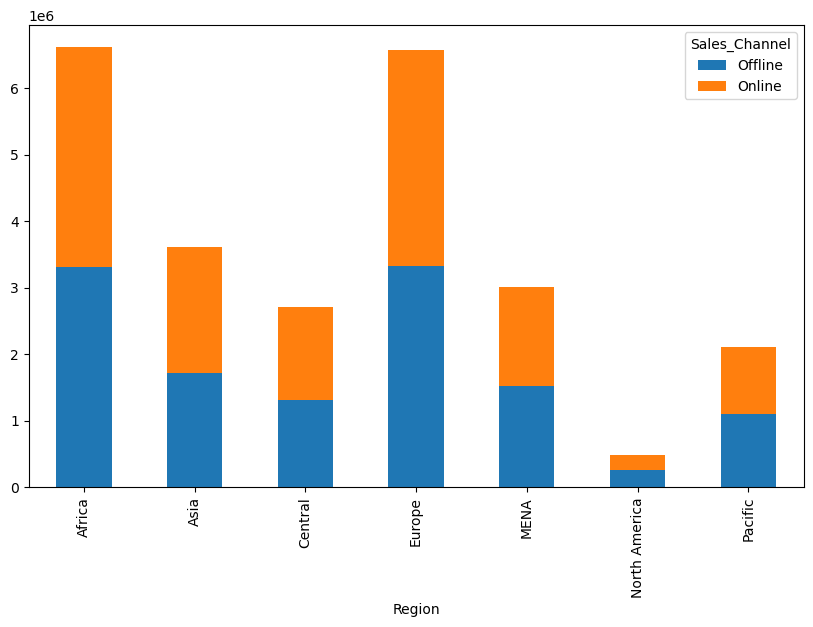

In [30]:
import matplotlib.pyplot as plt

# 1. Create the figure and axes objects explicitly

# 2. Plot the stacked bar chart directly on the ax object


# 3. Use axes methods for setting titles, labels, and ticks


# 4. Configure tick rotation and legend through the axes object


# 5. Display the plot

#provide the total units sold by  by region and sales_channel

stacked = df.groupby(['Region', 'Sales_Channel'])['Units_Sold'].sum().unstack()




fig, ax = plt.subplots(figsize=(10, 6))

# 2. Plot the stacked bar chart directly on the ax object

stacked.plot(

    kind='bar',

    stacked=True,

    ax=ax,

    color=['#1f77b4', '#ff7f0e'],

)







<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.4 Pie Chart </h5>
</div>


In [27]:
#1
#1

 

#df.columns

 

Priority_counts = df['Order_Priority'].value_counts()

 

Priority_counts







Order_Priority
Medium       1321
High         1278
Low          1227
Cancelled    1173
Name: count, dtype: int64

([<matplotlib.patches.Wedge at 0x169b9458190>,
 [Text(0.7422214322622864, 0.8118542637016328, 'Medium'),
  Text(-0.8566485311073591, 0.6900386178697567, 'High'),
  Text(-0.687073071767639, -0.8590288668326467, 'Low'),
  Text(0.8144150626096615, -0.7394106476069312, 'Cancelled')])

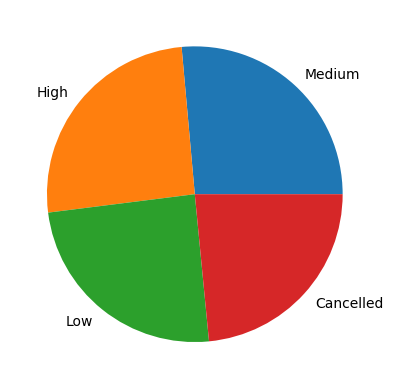

In [28]:
#2
#2

 

plt.pie(

    x=Priority_counts,              

    labels=Priority_counts.index)







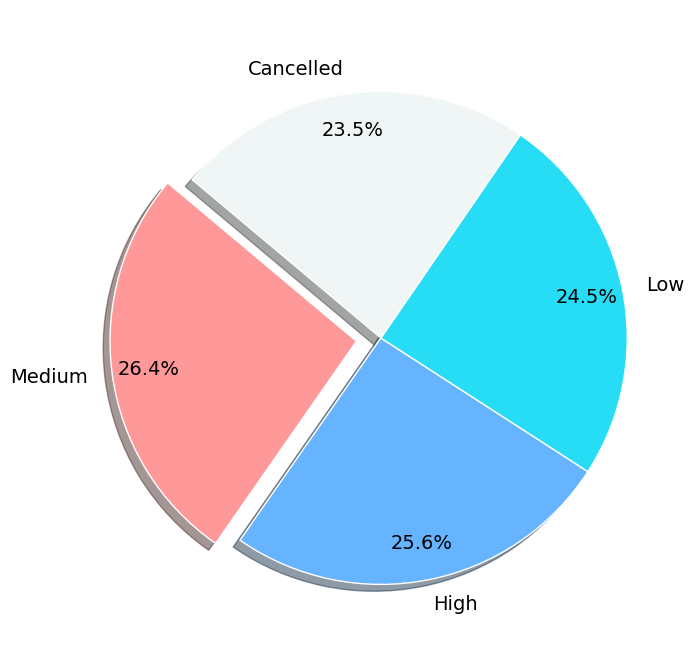

In [32]:
plt.figure(figsize=(10, 8))

 

 

plt.pie(

    x=Priority_counts,              # The numerical data

    labels=Priority_counts.index,   # The text labels for each slice

    autopct='%1.1f%%',              # Format for the percentage values

    startangle=140,                 # Rotates the start of the chart

    pctdistance=0.85,               # Distance of % from center (0 to 1)

    labeldistance=1.1,              # Distance of labels from center

    explode=[0.1, 0, 0, 0],         # "Pulls out" the first slice for emphasis

    shadow=True,                    # Adds a 3D shadow effect

    colors=['#ff9999','#66b3ff','#27DDF5', '#F0F5F5'],   # Custom hex color palette

    textprops={'fontsize': 14, 'color':  'black'},     # Dictionary of font properties for all text

    wedgeprops={'edgecolor': 'w'},  # Properties for the slice edges (e.g., white borders)

    counterclock=True,              # Direction of the slices

    center=(0, 0),                  # Center of the chart

    radius=1.0,                     # Radius of the pie

    rotatelabels=False              # If True, rotates labels to slice angle

)

 

plt.title(' ')

plt.show()






<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.5 Line Chart </h5>
</div>


In [35]:
# Aggregate units sold by date
# Aggregate units sold by date

trend = df.groupby(df['Ship_Date'].dt.year)['Units_Sold'].sum()

trend






Ship_Date
2015    3488765
2016    3187053
2017    2087929
2018    3041789
2019    3353131
2020    3486959
2021    3346730
2022    3136565
Name: Units_Sold, dtype: int64

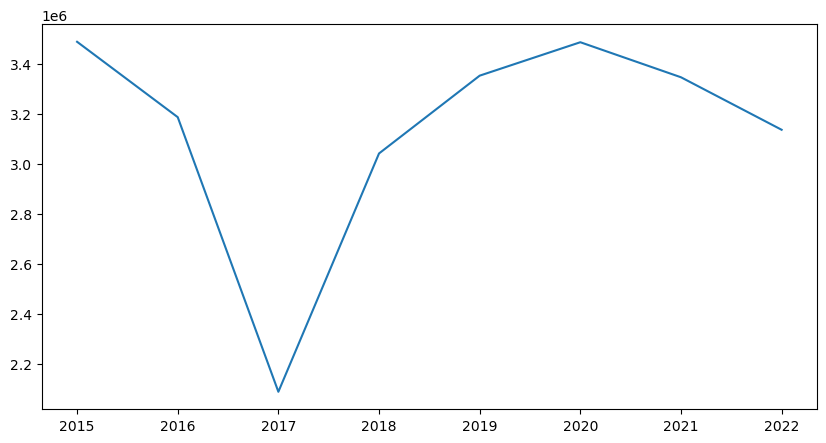

In [36]:
# 1. Create the figure and axis

fig, ax = plt.subplots(figsize=(10, 5))

 

# 2. Plot the data (ax.plot creates a line plot by default)

ax.plot(trend.index, trend.values)

 

# 3. Display the plot

plt.show()






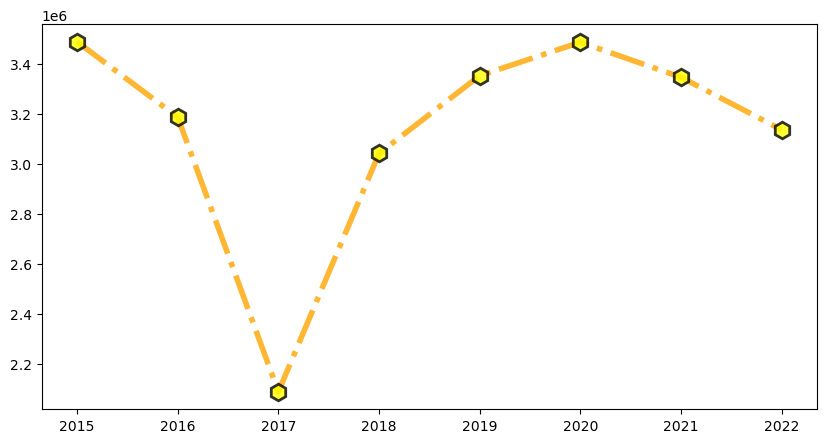

In [37]:
import matplotlib.pyplot as plt

# 1. Create the figure and axes objects explicitly

# 2. Plot using the ax object instead of plt


# Show the plot
import matplotlib.pyplot as plt

 

# 1. Create the figure and axes objects explicitly

fig, ax = plt.subplots(figsize=(10, 5))

 

# 2. Plot using the ax object instead of plt

ax.plot(

    trend.index,  # X-axis data

    trend.values,  # Y-axis data

    color='orange',  # Line color

    linestyle='-.',  # Line style (dash-dot)

    linewidth=4,  # Thickness of the line

    marker='h',  # Marker shape (hexagon)

    markersize=12,  # Size of the markers

    markerfacecolor='yellow',  # Color of the marker interior

    markeredgecolor='black',  # Color of the marker border

    markeredgewidth=2,  # Thickness of the marker border

    alpha=0.8,  # Transparency (0 to 1)

    label='Projected Growth',  # Label for the legend

    zorder=5,  # Layer priority

    solid_capstyle='round',  # How the ends of the line look

)

 

# Show the plot

plt.show()






<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.6 Area Chart </h5>
</div>


In [38]:
#data
#data

# for the year 2021, group the sales data by month

 

 

df[df['Order_Date'].dt.year == 2021].groupby('Order_Month')['Units_Sold'].sum()






Order_Month
2021-01-01    250178
2021-02-01    272237
2021-03-01    310227
2021-04-01    188015
2021-05-01    312695
2021-06-01    239999
2021-07-01    319551
2021-08-01    277415
2021-09-01    302131
2021-10-01    284938
2021-11-01    271285
2021-12-01    318059
Name: Units_Sold, dtype: int64

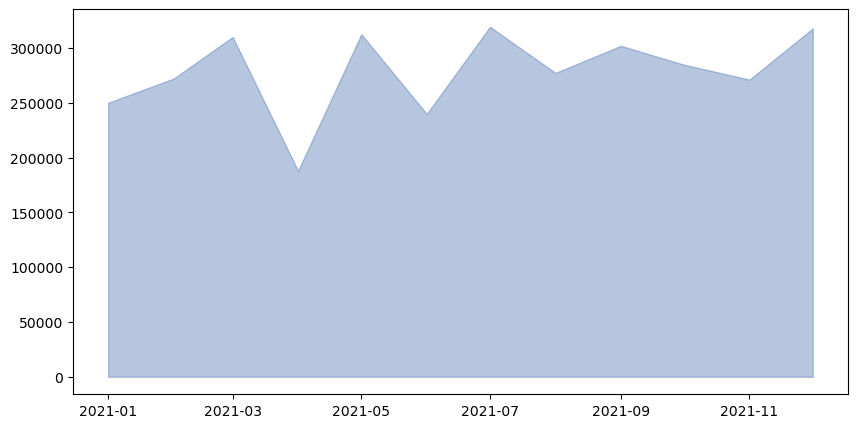

In [39]:


# 1. Create the figure and axes objects

# 2. Convert the line plot to an area chart using ax.fill_between()


# 3. Add the border line on top of the filled area for better definition


# 4. Configure titles, labels, and grid settings

# 5. Clean up the borders

# 6. Save and display the plot

monthly_revenue = df[df['Order_Date'].dt.year == 2021].groupby('Order_Month')['Units_Sold'].sum()

 

 

# 1. Create the figure and axes objects

 

fig, ax = plt.subplots(figsize=(10, 5))

 

 

# 2. Convert the line plot to an area chart using ax.fill_between()

 

ax.fill_between(

    monthly_revenue.index,

    monthly_revenue.values,

    color='#4C72B0',

    alpha=0.4,  # Transparency for the filled area

)







<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.7 SubPlots in Matplotlib </h5>
</div>

[Text(0, 1900000, '1.9M'), Text(0, 2100000, '2.1M'), Text(0, 2300000, '2.3M')]

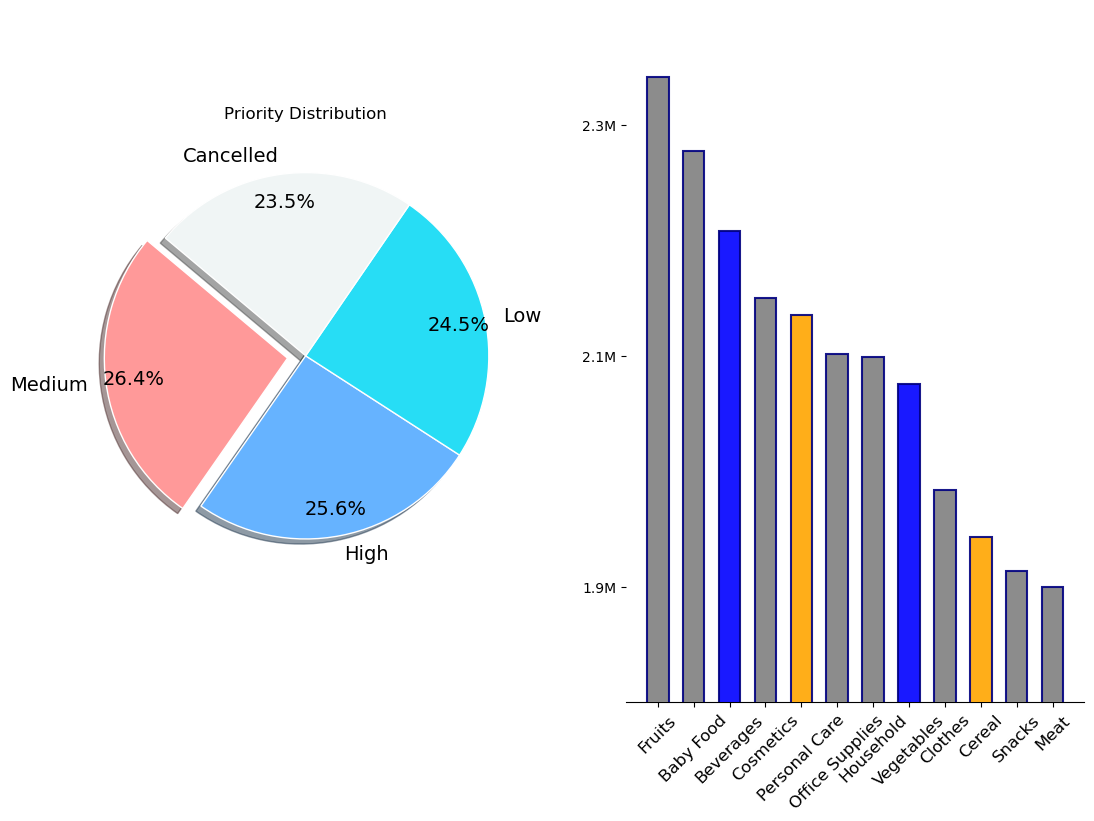

In [42]:

# 1. Create a single figure with 1 row and 2 columns of subplots

# Unpack the axes array into individual variables for clarity



# 2. FIRST PLOT: Pie Chart (placed in ax1)



# Set title for the first subplot



# 2. SECOND PLOT: Bar Chart (placed in ax2)


# Configure x-axis tick labels and rotation on ax2

# Remove unnecessary top, right, and left borders from ax2


# Set limits and custom ticks for the y-axis on ax2


# ==========================================
# 4. Finalize and Display the Multi-plot Figure
# ==========================================
# Automatically adjust layout elements so they don't overlap

# Render both plots together

# 1. Create a single figure with 1 row and 2 columns of subplots

fig, axes = plt.subplots(1, 2, figsize=(13, 9))

# Unpack the axes array into individual variables for clarity
ax1, ax2 = axes
ax1.pie(

    x=Priority_counts,

    labels=Priority_counts.index,

    autopct='%1.1f%%',

    startangle=140,

    pctdistance=0.85,

    labeldistance=1.1,

    explode=[0.1, 0, 0, 0],

    shadow=True,

    colors=['#ff9999', '#66b3ff', '#27DDF5', '#F0F5F5'],

    textprops={'fontsize': 14, 'color': 'black'},

    wedgeprops={'edgecolor': 'w'},

    counterclock=True,

    center=(0,0),

    radius=1.0,

    rotatelabels=False,

)

 

# Set title for the first subplot

ax1.set_title('Priority Distribution')


# 2. SECOND PLOT: Bar Chart (placed in ax2)

 

my_colors = ['grey', 'grey', 'blue', 'grey', 'orange']

 

ax2.bar(

    sumofunits.index,  # X-axis: Categories

    sumofunits.values,  # Y-axis: Numeric values

    width=0.6,  # Thickness of the bars

    color=my_colors,  # List of colors

    edgecolor='navy',  # Color of the bar border

    linewidth=1.5,  # Thickness of the border

    alpha=0.9,  # Transparency

    label='Q3 Revenue',  # Label for legend

    capsize=4,  # Width of the horizontal caps on error bars

    align='center',  # Alignment of the bar on the x-tick

    bottom=0,  # The base y-coordinate

    zorder=3,  # Drawing order

)

 

# Configure x-axis tick labels and rotation on ax2

ax2.set_xticks(range(len(sumofunits.index)))

ax2.set_xticklabels(sumofunits.index, rotation=45, fontsize=12, color='black')

 

# Remove unnecessary top, right, and left borders from ax2

ax2.spines['top'].set_visible(False)

ax2.spines['right'].set_visible(False)

ax2.spines['left'].set_visible(False)

 

# Set limits and custom ticks for the y-axis on ax2

ax2.set_ylim(1800000, 2400000)

ax2.set_yticks([1900000, 2100000, 2300000])

ax2.set_yticklabels(['1.9M', '2.1M', '2.3M'])


<div class="alert" style="background-color:maroon; color:#800000; padding:0px 5px; border-radius:5px;"><h3 style='margin:15px 15px; color:#ffffff; font-size:30px'> Seaborn </h3>
</div>


Seaborn is a statistical visualization library that sits on top of Matplotlib the same way Pandas' `.plot()` does.
Every Seaborn function ultimately calls Matplotlib to draw, and every Seaborn function returns a real Matplotlib `Axes` 

What Seaborn adds on top:

1. Works directly with tidy DataFrames - you pass `data=df, x='col', y='col'` instead of extracting arrays yourself.
2. Better default themes - `sns.set_theme()` immediately improves colors, fonts, and spacing versus Matplotlib's bare defaults.


In [46]:
import warnings
warnings.filterwarnings('ignore')

tips = sns.load_dataset('tips')

tips.head(10)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
5,25.29,4.71,Male,No,Sun,Dinner,4
6,8.77,2.00,Male,No,Sun,Dinner,2
7,26.88,3.12,Male,No,Sun,Dinner,4
8,15.04,1.96,Male,No,Sun,Dinner,2
9,14.78,3.23,Male,No,Sun,Dinner,2


In [47]:
tips.shape

sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.1 Distribution Plots </h5>
</div>


1. A distribution plot comprises of 3 plots each of which may be toggled ON or OFF.
2. By default, Histogram and KDE are set to ON , whereas RUG Plot is set to OFF .
3. The KDE or histogram may be turned OFF by specifying kde=False or hist=False argument respectively.
4. Likewise, RUG plot can be turned ON, using rug=True argument
5. Individual plots within a Distribution plot can be further customized.
6. The custom parameters are specified as a dictionary — key:value pair. In the below example, we’ve the 3 plots set to ON.
7. There are five preset seaborn themes: darkgrid, whitegrid, dark, white, and ticks. Below, I set the theme as dark

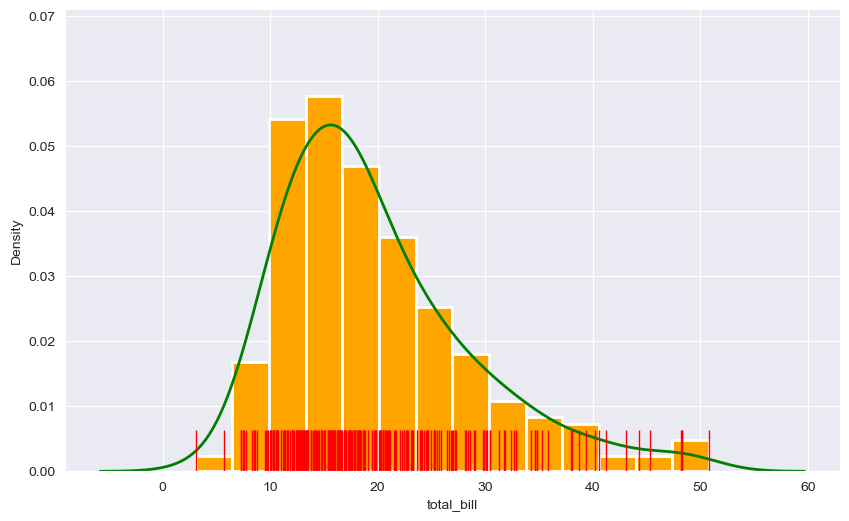

In [48]:
plt.figure(figsize=(10, 6))

 

sns.set_style("darkgrid")

 

sns.distplot(tips['total_bill']

             , hist_kws={"linewidth":2,"alpha": 1,"color": "orange"}

             , kde = True

             , kde_kws={"color":"g", "lw":2}

             , rug=True

             , rug_kws={"color":"red","height":0.09}

             );






<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.2 Joint Plots </h5>
</div>

1. A Joint Plot allows matching of 2 dist plots for bi-variate data.

2. Bivariate analysis is one of the simplest forms of quantitative analysis.

3. It involves the analysis of two variables (often denoted as X, Y), for the purpose of determining the empirical relationship between them . https://seaborn.pydata.org/generated/seaborn.jointplot.html

4. From the tips data set; plot the total_bill and tip; to try and understand a relation ship between the bivariate data columns

5. The scatter plots shows us the relationsip between the 2 values.

6. At the edge, the histogram - shows frequency distribution of the 2 variables.



<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.3 Box and Whisker </h5>
</div>


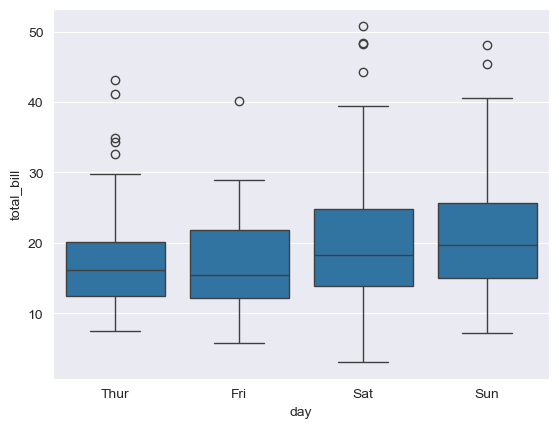

In [50]:
#A box and whisker plot for entire range of data
sns.boxplot(x='day'

            , y='total_bill'

            , data=tips);






Let us dive deep into analyzing a Box and whisker plot
Let's zero down to the day with least number of customers visiting the restaurant - which is Friday

1. Calculate the IQR: IQR (Inter Quartile Range)= Q3-Q1 or 75th - 25th (21.75- 12.09) = 9.655.
2. Maximum Value = Q3 + (1.5 * IQR) = 75% + (1.5 * 9.655) < outlier
3. Maximum Value = Q1 - (1.5 * IQR) = 25% - (1.5 * 9.655) > outlier



- Outliers on the higher side Q3 + (1.5 * IQR),
- Outliers on the lower side is Q1 — (1.5*IQR).
- IQR stands for Inter quartile range and is the difference between the Q3 & Q1 values.
- In this case 21.75–12.095 = 9.655.
- Any value beyond (21.75 + 9.655) = 31.405 is treated as an outlier.
- 40.17 is way way way far away from 31.04, no wonder the plot treats the data point as an outlier.
- A Box and whisker plot for the entire range of data

Now, I shall leave this to you; so you may tally the numbers with the plot ..Easy peazy !! In case; you're wondering about the two different plots. The argument hue which maps to 'sex' helps split categorical data (male/female)

<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h3 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.4 Violin Plot </h3>
</div>


- A violin plot helps represent comparison of a variable distribution across "categories" .
- A violin plot differs from a Box plot in a way that it provides with the density distribution of data points

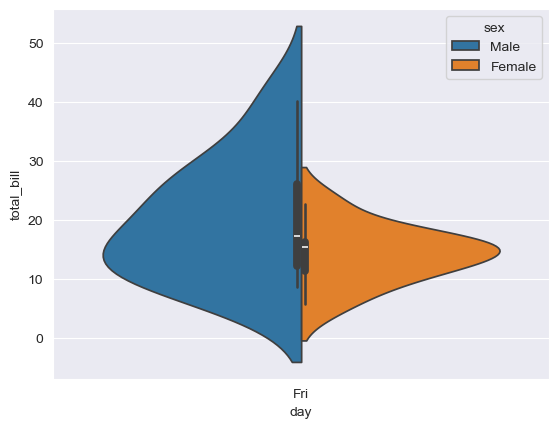

In [52]:
sns.violinplot(x='day'

               , y ='total_bill'

               , data =(tips[tips['day'] =='Fri'][['day','total_bill','sex']])

               ,split=True

               ,hue='sex'

               ,order=['Fri']);






<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h3 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.5 SCATTER, STRIP & SWARM PLOTS </h3>
</div>


- Strip plots are a good alternative to Scatter plots when visually capturing all, especially overlapping data points in an observation. 
- Unlike a scatter plot, where 2 similar data points are superimposed, a strip plot juxtaposes the values (argument — jitter=‘True’)

<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.5.1 Scatter Plot </h5>
</div>


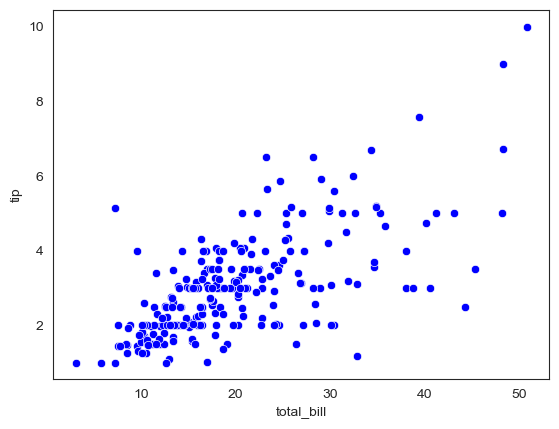

In [54]:
sns.scatterplot(x='total_bill', y ='tip', data=tips, color = 'blue');

<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.5.2 Strip Plot </h5>
</div>


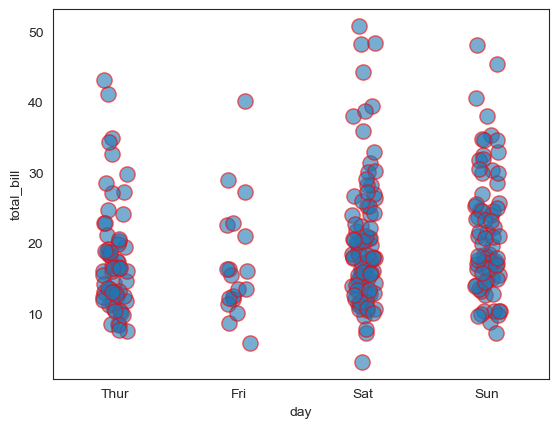

In [53]:
#choose the grid-style

sns.set_style("white")

 

sns.stripplot(x='day'

              , y ='total_bill'

              , data =tips

              , jitter=True

              , alpha=0.6

              , size=11

              , edgecolor ='red'

              , linewidth=1);






<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h5 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.5.3 Swarm Plot </h5>
</div>


- The plots resemble a swarm of bees and hence the name.
- A swarm plot is a categorical scatter plot, similar to a strip plot except that
- The location of points are automatically adjusted to avoid overlap even if the jitter value is not applied.

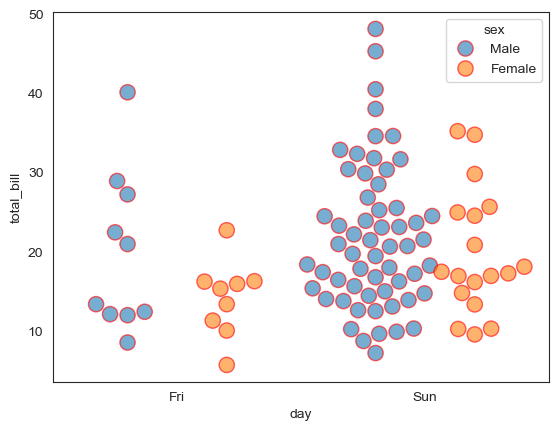

In [55]:
sns.swarmplot(x='day'

              , y ='total_bill'

              , data =tips

              , alpha=0.6

              , size=11 

              , order =['Fri','Sun']

              , edgecolor ='red'

              , hue ='sex'

              , linewidth=1

              , dodge=True);






<div class="alert" style="background-color:#1F2F45; color:White; padding:0px 5px; border-radius:5px;"><h3 style='margin:15px 15px; color:#ffffff; font-size:20px'> 1.6. Heatmap </h3>
</div>


A Heatmap Plots the datapoints in the form of a matrix. It helps study correlation between datapoints. For the purpose of illustration, I download flights dataset availble in seaborn library and rearrange the colums

- Can be used to show trends and seasonality
- Can be used to show collinearity between datapoints

In [56]:
fp = sns.load_dataset('flights')

flights = fp.pivot_table(index='month', columns ='year', values ='passengers')

 

flights






year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112.0,115.0,145.0,171.0,196.0,204.0,242.0,284.0,315.0,340.0,360.0,417.0
Feb,118.0,126.0,150.0,180.0,196.0,188.0,233.0,277.0,301.0,318.0,342.0,391.0
Mar,132.0,141.0,178.0,193.0,236.0,235.0,267.0,317.0,356.0,362.0,406.0,419.0
Apr,129.0,135.0,163.0,181.0,235.0,227.0,269.0,313.0,348.0,348.0,396.0,461.0
May,121.0,125.0,172.0,183.0,229.0,234.0,270.0,318.0,355.0,363.0,420.0,472.0
Jun,135.0,149.0,178.0,218.0,243.0,264.0,315.0,374.0,422.0,435.0,472.0,535.0
Jul,148.0,170.0,199.0,230.0,264.0,302.0,364.0,413.0,465.0,491.0,548.0,622.0
Aug,148.0,170.0,199.0,242.0,272.0,293.0,347.0,405.0,467.0,505.0,559.0,606.0
Sep,136.0,158.0,184.0,209.0,237.0,259.0,312.0,355.0,404.0,404.0,463.0,508.0


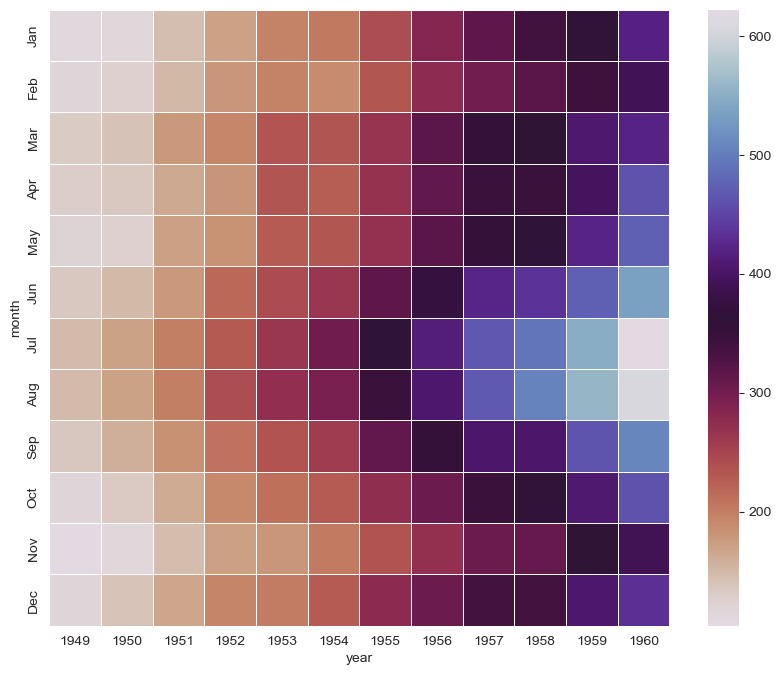

In [58]:
plt.figure(figsize=(10,8))

 

sns.heatmap(flights

            , cmap ='twilight_r'

            , linecolor ='white'

            ,linewidth =0.4

            ,annot=False);


